# Exercise 2: Data Processing and Analysis

In [13]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
try:
    import otter
    grader = otter.Notebook()
except:
    !pip install otter-grader
    import otter
    grader = otter.Notebook()

Today we're working with simulated smartwatch health data. You'll notice when you read in the csv file that we have 7 columns: User ID, Heart Rate (BPM), Blood Oxygen Level (%), Step Count, Sleep Duration (hours), Activity Level, and Stress Level. We're going to go through and "clean up" the data so that we can calculate some basic statistics such as mean, median, minimum, and maximum for each variable. Run the cell below to read in the table saving it in the variable `smartwatch`. 

In [14]:
smartwatch = pd.read_csv("unclean_smartwatch_health_data.csv")
smartwatch

,User ID,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level
0,4174.0,58.939776,98.809650,5450.390578,7.167235622316564,Highly Active,1
1,NaN,NaN,98.532195,727.601610,6.538239375570314,Highly_Active,5
2,1860.0,247.803052,97.052954,2826.521994,ERROR,Highly Active,5
3,2294.0,40.000000,96.894213,13797.338044,7.367789630207228,Actve,3
4,2130.0,61.950165,98.583797,15679.067648,NaN,Highly_Active,6
...,...,...,...,...,...,...,...
9995,1524.0,78.819386,98.931927,2948.491953,7.402748595032027,Active,7
9996,4879.0,48.632659,95.773035,4725.623070,6.3821659358529015,Sedentary,2
9997,2624.0,73.834442,97.945874,2571.492060,6.91654920303435,Sedentary,4
9998,4907.0,NaN,98.401058,3364.788855,5.691233932149209,Active,8


Let's start together with the Heart Rate column. Just looking at the preview table above we can see two things right away: (1) we have `NaN` values meaning data was not collected for those individuals, and (2) some of the heart rate values are abnormally high i.e. `247.803052`. Let's see what the entire range of values look like. 

In [15]:
print(smartwatch['Heart Rate (BPM)'].min(), smartwatch['Heart Rate (BPM)'].max())

40.0 296.5939695131042


**Question 1**: Set the variables below equal to the minimum heart rate and the maximum heart rate in the dataset. This is just practice for the method of checking answers as you go. Afterwards run the cell below to check your answer. 

In [16]:
minimumHeartRate = smartwatch['Heart Rate (BPM)'].min()
maximumHeartRate = smartwatch['Heart Rate (BPM)'].max()

In [17]:
grader.check('q1')

Question 1 results: All test cases passed!

Notice that the maximum value of `296` beats per minimute is WAY above normal range of heart rates. In fact, according to [heart.org](https://www.heart.org/en/healthy-living/fitness/fitness-basics/target-heart-rates) the highest estimated heart rate based on age ranges from 150 to 200 for adults. This will vary between individuals, but this is a good starting point for us to think about outliers in the heart rate values in this dataset. Let's see how many rows have missing data or heart rates above 200. 

In [18]:
## select rows where Heart Rate is NaN or rows where the heart rate is above 200. 
# Emphasis on the usage of 'or' here, we want rows where either 
# scenario 1 (NaN) OR scenario 2 (>200) is true. 

outlierHeartRaterows = smartwatch[smartwatch['Heart Rate (BPM)'] > 200]
nullHeartRaterows = smartwatch[smartwatch['Heart Rate (BPM)'].isnull()]

print(len(outlierHeartRaterows) + len(nullHeartRaterows))

450


In [19]:
print(nullHeartRaterows)

      User ID  Heart Rate (BPM)  Blood Oxygen Level (%)    Step Count  \
1         NaN               NaN               98.532195    727.601610   
17     3919.0               NaN               96.052853   3488.919508   
75     3945.0               NaN              100.000000   3124.118038   
105    2981.0               NaN               98.276558   3039.112276   
158    4099.0               NaN               99.478461  11559.663606   
...       ...               ...                     ...           ...   
9875      NaN               NaN               99.842527   4454.770218   
9956   1476.0               NaN              100.000000   3584.236177   
9971   1434.0               NaN               99.319841     26.215769   
9990      NaN               NaN              100.000000   3817.269018   
9998   4907.0               NaN               98.401058   3364.788855   

     Sleep Duration (hours) Activity Level Stress Level  
1         6.538239375570314  Highly_Active            5  
17     

In [20]:
## Now let's get a table of all the other rows. 
heartrateRows = smartwatch[(~smartwatch['Heart Rate (BPM)'].isnull()) & (smartwatch['Heart Rate (BPM)'] <= 200)]

print(heartrateRows)

      User ID  Heart Rate (BPM)  Blood Oxygen Level (%)    Step Count  \
0      4174.0         58.939776               98.809650   5450.390578   
3      2294.0         40.000000               96.894213  13797.338044   
4      2130.0         61.950165               98.583797  15679.067648   
5      2095.0         96.285938               94.202910  10205.992256   
6      4772.0         47.272257               95.389760   3208.781177   
...       ...               ...                     ...           ...   
9994   1942.0         77.912299               98.640583  10061.145291   
9995   1524.0         78.819386               98.931927   2948.491953   
9996   4879.0         48.632659               95.773035   4725.623070   
9997   2624.0         73.834442               97.945874   2571.492060   
9999   4113.0         70.063864               98.475606    544.696104   

     Sleep Duration (hours) Activity Level Stress Level  
0         7.167235622316564  Highly Active            1  
3      

**Question 2:** 

Notice here that the length of the two tables (`450` and `9550`) add up to the total number rows (`n=10000`). This is a good sanity check as we manipulate the table. Now we have to decide how we deal with these missing values and outliers. One method to do this would be remove all the rows with null values or outlier values. Another method is use imputation - this can be done in several ways but below we're going to substitute the average heart rate for the missing and mismeasured values. Do we think this will change the mean?

In [21]:
HeartRateMean = heartrateRows['Heart Rate (BPM)'].mean()
print(HeartRateMean)


75.13268404820141


In [22]:
outlierHeartRaterows['Heart Rate (BPM)'] = HeartRateMean
nullHeartRaterows['Heart Rate (BPM)'] = HeartRateMean


print(outlierHeartRaterows)

      User ID  Heart Rate (BPM)  Blood Oxygen Level (%)    Step Count  \
2      1860.0         75.132684               97.052954   2826.521994   
337    2369.0         75.132684               95.441773   2998.761919   
393    2443.0         75.132684               95.497181   1227.804688   
403    3200.0         75.132684               96.011492   9402.746140   
595    2129.0         75.132684               97.161853   2555.402184   
649    2008.0         75.132684               98.356789   2739.171166   
818    3156.0         75.132684                     NaN   7281.778831   
1195   3261.0         75.132684               99.652006   2867.872064   
1391   4621.0         75.132684               96.688083  20577.677290   
1602   4737.0         75.132684               95.095839  16072.283561   
2023      NaN         75.132684               99.032130  17620.765455   
2211   2711.0         75.132684               97.852781   1786.998129   
2212   4020.0         75.132684               95.28

/tmp/ipykernel_1712/936369900.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  outlierHeartRaterows['Heart Rate (BPM)'] = HeartRateMean
/tmp/ipykernel_1712/936369900.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nullHeartRaterows['Heart Rate (BPM)'] = HeartRateMean


In [23]:
smartwatch_hr = pd.concat([outlierHeartRaterows, nullHeartRaterows, heartrateRows])

fullTableHRMean = smartwatch_hr['Heart Rate (BPM)'].mean()
print(fullTableHRMean)

75.13268404820141


In [24]:
grader.check('q2')

Question 2 results:
    Question 2 - 1 result:
        ❌ Test case failed
        Trying:
            bool((HeartRateMean == 75.13268404820141) or (HeartRateMean == np.float64(75.13268404820141)))
        Expecting:
            True
        ok
        Trying:
            HeartRateMean == fullTableHRMean
        Expecting:
            True
        **********************************************************************
        Line 5, in Question 2 0
        Failed example:
            HeartRateMean == fullTableHRMean
        Expected:
            True
        Got:
            np.True_

Notice how the mean doesn't change when you use the imputed mean as the substituted values. However, as a note this will change the distribution of values and has the potential to obscure the causes of missing values or outliers. 

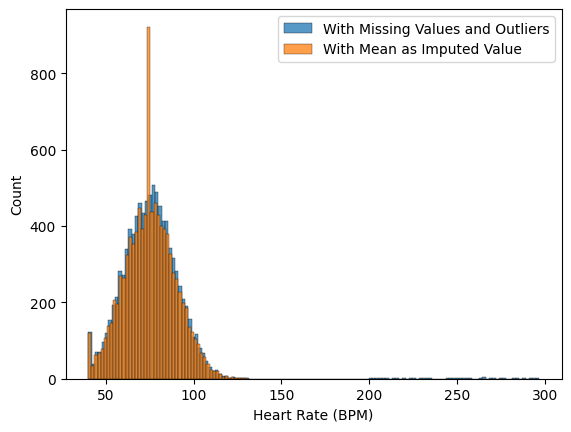

In [25]:
sns.histplot(smartwatch['Heart Rate (BPM)'], label ='With Missing Values and Outliers')
sns.histplot(smartwatch_hr['Heart Rate (BPM)'], label = 'With Mean as Imputed Value')
plt.legend()

**Question 3**: How does the imputation method affect the median values?  Remember the table `smartwatch` remains unchanged and can be used to find the original median value. 

ANSWER: 
We got a slight decrease from 75.22 to 75.15 when we used imputation because we made the outliers into the mean values. This skewed the median closer to the mean.

In [26]:
## coding cell to check the difference in median values 

print(heartrateRows['Heart Rate (BPM)'].median())
print(smartwatch['Heart Rate (BPM)'].median())


75.14626274239524
75.22060125775644


Now let's repeat this process for the other columns as well. 

**Question 4**: Find the minimum, maximum, and mean Blood Oxygen Level. 

In [27]:
minBloodO2 = smartwatch['Blood Oxygen Level (%)'].min()

maxBloodO2 = smartwatch['Blood Oxygen Level (%)'].max()

meanBloodO2 = smartwatch['Blood Oxygen Level (%)'].mean()

print(minBloodO2, maxBloodO2, meanBloodO2)

90.79120814564097 100.0 97.84158102099076


In [28]:
grader.check('q4')

Question 4 results: All test cases passed!

We can do some visualizations using a box plot to better decide if there's any outliers we'd like to remove. Maybe you decide that everything below 92.5 is an outlier should be removed or maybe you decide to keep all of the values or maybe you decide to remove all values under 94% since that falls outside of a normal, healthy range according to doctors (I would not suggest this last one as it would obscure quite a bit of data! But some analysts might consider it!). In question 5, you can make that decision and justify your answer. 

<Axes: ylabel='Blood Oxygen Level (%)'>

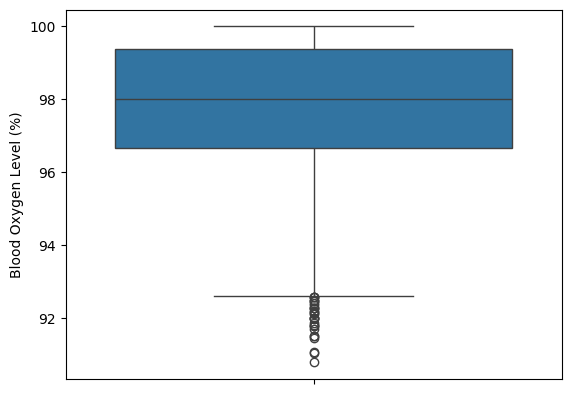

In [29]:
sns.boxplot(smartwatch['Blood Oxygen Level (%)'])

**Question 5**: Decide how you want to deal with missing and outlier values in the Blood Oxygen Level column. Set your final table equal to the variable `smartwatch_o2`. Use the space below to explain your decisions. 

Notes: Refer to [this article](https://pmc.ncbi.nlm.nih.gov/articles/PMC5548942/) on methods of handling these type of instances in data. Keep in mind, you might find that either there are no missing values or no outliers. That's okay, just indicate that in the written space below and update the table i.e. `smartwatch_o2 = smartwatch_hr`

ANSWER: I chose to utilize imputation again because I like how it keeps the rest of the data in that row usable while maintaining the statistical integrity of that column.

....

In [30]:
## use this space or additional cells to deal with the missing/outlier values. 
nullBlood02rows = smartwatch_hr[smartwatch_hr['Blood Oxygen Level (%)'].isnull()]
nullBlood02rows['Blood Oxygen Level (%)'] = meanBloodO2
smartwatch_o2 = pd.concat([nullBlood02rows,smartwatch_hr[~smartwatch_hr['Blood Oxygen Level (%)'].isnull()]])

print(smartwatch_o2)

      User ID  Heart Rate (BPM)  Blood Oxygen Level (%)    Step Count  \
818    3156.0         75.132684               97.841581   7281.778831   
8369   2283.0         75.132684               97.841581  21495.639335   
1615   1417.0         75.132684               97.841581   1585.892722   
1712   4079.0         75.132684               97.841581  19003.921284   
4690   2829.0         75.132684               97.841581   6610.794796   
...       ...               ...                     ...           ...   
9994   1942.0         77.912299               98.640583  10061.145291   
9995   1524.0         78.819386               98.931927   2948.491953   
9996   4879.0         48.632659               95.773035   4725.623070   
9997   2624.0         73.834442               97.945874   2571.492060   
9999   4113.0         70.063864               98.475606    544.696104   

     Sleep Duration (hours) Activity Level Stress Level  
818       4.300171191258864      Sedentary            3  
8369   

/tmp/ipykernel_1712/3804273157.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nullBlood02rows['Blood Oxygen Level (%)'] = meanBloodO2


Moving onto the Step Count column. 

**Question 6**: Find the minimum, maximum, and mean step counts. 

In [31]:
minSteps = smartwatch['Step Count'].min()

maxSteps = smartwatch['Step Count'].max()

meanSteps = smartwatch['Step Count'].mean()

print(minSteps, maxSteps, meanSteps)

0.9101380609604088 62486.690753464914 6985.685884992229


In [32]:
grader.check('q6')

Question 6 results: All test cases passed!

**Question 7**: Decide how you want to deal with missing and outlier values in the Steps column. Set your final table equal to the variable `smartwatch_steps`. Use the space below to explain your decisions. 

Notes: Refer to [this article](https://pmc.ncbi.nlm.nih.gov/articles/PMC5548942/) on methods of handling these type of instances in data. Keep in mind, you might find that either there are no missing values or no outliers. That's okay, just indicate that in the written space below and update the table i.e. `smartwatch_steps = smartwatch_o2`

ANSWER: 
I decided to keep all values the same because some people do not walk in their daily life, and some people are avid hikers. All the data is useful.

In [36]:
## use this space or additional cells to address the missing or outlier data. 

smartwatch_steps = smartwatch_o2


Next onto the Sleep Duration column. 

**Question 8**: Try finding the minimum number of hours slept among participants. 

In [37]:
minSleep = smartwatch['Sleep Duration (hours)'].min()

print(minSleep)

TypeError: '<=' not supported between instances of 'str' and 'float'

In the error message, you should see the phrase: 

`TypeError: '<=' not supported between instances of 'str' and 'float'`

This means that the column is a combination of multiple data types. If you recall, we discussed computer readable data that columns HAVE to contain just a single data type. Having a combination of strings, characters, and numbers in a column will only cause more issues downstream. Let's try to figure out all the instances of non-numerical values in the column. 

First let's try to identify all the non-numerical values to make sure removing them doesn't obscure any important information. 

In [38]:
for value in smartwatch['Sleep Duration (hours)'].unique():  ## Loop through each unique item in the column
    try:
        numericVal = float(value)  ## first try to see if it can be converted to a number
    except:
        print(value)  ## if it can't be converted print it to screen 

ERROR


So, we find that the only non-numerical value is the string `ERROR`. We can fix this in two ways. First let's try fixing it by splitting the tables like we've done previously. 

In [39]:
errorTable = smartwatch_steps[smartwatch_steps['Sleep Duration (hours)'] == 'ERROR']
errorTable

,User ID,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level
711,2066.0,64.843081,97.841581,12722.224091,ERROR,Seddentary,7
1245,1484.0,91.329653,97.841581,522.951192,ERROR,Sedentary,7
1335,1193.0,57.231545,97.841581,2184.899471,ERROR,Highly_Active,5
4500,2800.0,72.615444,97.841581,5667.748281,ERROR,Sedentary,6
6035,4721.0,56.758561,97.841581,430.504664,ERROR,Seddentary,4
...,...,...,...,...,...,...,...
9901,2269.0,63.369107,96.229029,6656.786482,ERROR,Active,4
9912,2074.0,75.933666,97.386073,1813.072248,ERROR,Sedentary,10
9927,3007.0,87.579045,98.768633,3727.161872,ERROR,Active,1
9943,2961.0,91.834863,96.145378,38831.465057,ERROR,Active,4


Observe that we've created a table with the rows with `ERROR` in the sleep duration column. We can now replace with the `ERROR` value with our handy NaN value for doing numerical statistics. 

In [40]:
errorTable['Sleep Duration (hours)'] = np.nan

errorTable

/tmp/ipykernel_1712/2302362292.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  errorTable['Sleep Duration (hours)'] = np.nan


,User ID,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level
711,2066.0,64.843081,97.841581,12722.224091,NaN,Seddentary,7
1245,1484.0,91.329653,97.841581,522.951192,NaN,Sedentary,7
1335,1193.0,57.231545,97.841581,2184.899471,NaN,Highly_Active,5
4500,2800.0,72.615444,97.841581,5667.748281,NaN,Sedentary,6
6035,4721.0,56.758561,97.841581,430.504664,NaN,Seddentary,4
...,...,...,...,...,...,...,...
9901,2269.0,63.369107,96.229029,6656.786482,NaN,Active,4
9912,2074.0,75.933666,97.386073,1813.072248,NaN,Sedentary,10
9927,3007.0,87.579045,98.768633,3727.161872,NaN,Active,1
9943,2961.0,91.834863,96.145378,38831.465057,NaN,Active,4


Now we could go through and put the tables back together, but another method to do this is to use a built-in function to pandas called `pd.to_numeric()`. Let's try that. 

In [41]:
## create a copy of the table 
smartwatch_sleep = smartwatch_steps

smartwatch_sleep['Sleep Duration (hours)'] = pd.to_numeric(smartwatch_sleep['Sleep Duration (hours)'], errors='coerce')

smartwatch_sleep

,User ID,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level
818,3156.0,75.132684,97.841581,7281.778831,4.300171,Sedentary,3
8369,2283.0,75.132684,97.841581,21495.639335,5.291654,Highly_Active,2
1615,1417.0,75.132684,97.841581,1585.892722,5.850088,Seddentary,9
1712,4079.0,75.132684,97.841581,19003.921284,5.612504,Active,2
4690,2829.0,75.132684,97.841581,6610.794796,7.770459,NaN,9
...,...,...,...,...,...,...,...
9994,1942.0,77.912299,98.640583,10061.145291,5.428635,Seddentary,10
9995,1524.0,78.819386,98.931927,2948.491953,7.402749,Active,7
9996,4879.0,48.632659,95.773035,4725.623070,6.382166,Sedentary,2
9997,2624.0,73.834442,97.945874,2571.492060,6.916549,Sedentary,4


Now we can finish **Question 8** and find the minimum, maximum, and mean of the sleep duration column. 

In [42]:
minSleep = smartwatch_sleep['Sleep Duration (hours)'].min()

maxSleep = smartwatch_sleep['Sleep Duration (hours)'].max()

meanSleep = smartwatch_sleep['Sleep Duration (hours)'].mean()

print(minSleep, maxSleep, meanSleep)

-0.1944527906201543 12.140232872862926 6.505462918406444


In [43]:
grader.check('q8')

Question 8 results: All test cases passed!

**Question 9**: Decide how you want to deal with missing and outlier values in the sleep column. Set your final table equal to the variable `smartwatch_updated_sleep`. Use the space below to explain your decisions. 

*Remember to start with the `smartwatch_sleep` table that we just created.*

Notes: Refer to [this article](https://pmc.ncbi.nlm.nih.gov/articles/PMC5548942/) on methods of handling these type of instances in data. Keep in mind, you might find that either there are no missing values or no outliers. That's okay, just indicate that in the written space below and update the table i.e. `smartwatch_updated_sleep = smartwatch_sleep`

ANSWER: 
Unfortunately I know many a college student who has pulled at least one all-nighter or tried to get by with under an hour of sleep in one night. Any data over zero is valuable. I will then use imputation to convert any errors or values under zero to the average so that the remainder of that row is still usable. Waste not.

In [44]:
sleepRows = smartwatch_steps[(~smartwatch_steps['Sleep Duration (hours)'].isnull()) & (smartwatch_steps['Sleep Duration (hours)'] > 0)]

In [45]:
## use this space or additional cells to address the missing or outlier data. 
sleepNull = smartwatch_sleep[smartwatch_sleep['Sleep Duration (hours)'].isnull()]
sleepOutliers = smartwatch_sleep[smartwatch_sleep['Sleep Duration (hours)']<0]
sleepOutliers['Sleep Duration (hours)'] = meanSleep
sleepNull['Sleep Duration (hours)'] = meanSleep
smartwatch_updated_sleep = pd.concat([sleepRows,sleepOutliers,sleepNull])
print(smartwatch_updated_sleep)


      User ID  Heart Rate (BPM)  Blood Oxygen Level (%)    Step Count  \
818    3156.0         75.132684               97.841581   7281.778831   
8369   2283.0         75.132684               97.841581  21495.639335   
1615   1417.0         75.132684               97.841581   1585.892722   
1712   4079.0         75.132684               97.841581  19003.921284   
4690   2829.0         75.132684               97.841581   6610.794796   
...       ...               ...                     ...           ...   
9901   2269.0         63.369107               96.229029   6656.786482   
9912   2074.0         75.933666               97.386073   1813.072248   
9927   3007.0         87.579045               98.768633   3727.161872   
9943   2961.0         91.834863               96.145378  38831.465057   
9951   3104.0         70.335328               98.560133   1997.442874   

      Sleep Duration (hours) Activity Level Stress Level  
818                 4.300171      Sedentary            3  
8369 

/tmp/ipykernel_1712/1225536674.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sleepOutliers['Sleep Duration (hours)'] = meanSleep
/tmp/ipykernel_1712/1225536674.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sleepNull['Sleep Duration (hours)'] = meanSleep


We're going to skip the `Activity Level` column for a minute and look at the `Stress Level` column. If we try getting the minimum, we'll find the same error as in the Sleep column where we have mixed data types (strings and numerical values). Let's use the same type of loop to make sure we don't obscure any data by forcing the strings to NaN values. 

In [46]:
for item in smartwatch_updated_sleep['Stress Level'].unique():
    try:
        int(item)
    except:
        print(item)

nan
Very High


**Question 10**: 

What might you decide to do to deal with the `Very High` value? 

Go ahead and do so below and give a brief case for doing so here. Assign your table to the variable `smartwatch_stress`. 

ANSWER: The stress column is graded on a scale from 1 to 10. I am going to make the executive decision to assign the value of 8 to the 'Very High' value-- 9 or 10 would be 'Extremely High' in my opinion, whereas 6 or 7 would be 'Rather High.'

In [48]:
## cell to deal with 'Very High' value
nonNumeric1 = smartwatch_updated_sleep[smartwatch_updated_sleep['Stress Level'] == 'Very High']
nonNumeric2 = smartwatch_updated_sleep[smartwatch_updated_sleep['Stress Level'].isnull()]
smartwatch_updated_sleep['Stress Level'] = pd.to_numeric(smartwatch_updated_sleep['Stress Level'], errors='coerce')
meanStress = smartwatch_updated_sleep['Stress Level'].mean()
nonNumeric1['Stress Level'] = 8
nonNumeric2['Stress Level'] = meanStress
Numeric = smartwatch_updated_sleep[~smartwatch_updated_sleep['Stress Level'].isnull()]
smartwatch_stress = pd.concat([nonNumeric1, nonNumeric2, Numeric])
print(smartwatch_stress['Stress Level'])
print(len(nonNumeric1))
print(len(nonNumeric2))
print(len(Numeric))

379      8.0
4302     8.0
5965     8.0
8691     8.0
494      8.0
        ... 
9901     4.0
9912    10.0
9927     1.0
9943     4.0
9951     9.0
Name: Stress Level, Length: 10000, dtype: float64
49
200
9751


/tmp/ipykernel_1712/3339410794.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nonNumeric1['Stress Level'] = 8
/tmp/ipykernel_1712/3339410794.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nonNumeric2['Stress Level'] = meanStress


Finally, let's go back to the `Activity Level` column and investigate what types of values we find there. 

In [49]:
smartwatch['Activity Level'].unique()

array(['Highly Active', 'Highly_Active', 'Actve', 'Seddentary',
       'Sedentary', 'Active', nan], dtype=object)

**Question 12**: 

What do you notice? There are several values that could and should be combined because they represent the same information. Let's go ahead and do that. While combining these columns, let's also create a new column `NumActivity` where we give a numerical value to represent the activity level. Assign your final table to the variable `final_table`. 

`Highly Active` = `1`

`Active` = `2`

`Sedentary` = `3`



In [50]:
## Highly Active 
highlyActive = smartwatch_stress[(smartwatch_stress['Activity Level'] == 'Highly_Active') | (smartwatch_stress['Activity Level'] == 'Highly Active')]  ## Pull out rows for two unique values matching highly active
highlyActive['Activity Level'] = 'Highly Active'  ## Reset the text in the column to either 'Highly Active'
highlyActive['NumActivity'] = 3 ## set the number for the numerical value 


## Active
active = smartwatch_stress[(smartwatch_stress['Activity Level'] == 'Active') | (smartwatch_stress['Activity Level'] == 'Actve')]
active['Activity Level'] = 'Active'
active['NumActivity'] = 2

## Sedentary 
sedentary = smartwatch_stress[(smartwatch_stress['Activity Level'] == 'Sedentary') | (smartwatch_stress['Activity Level'] == 'Seddentary')]
sedentary['Activity Level'] = 'Sedentary'
sedentary['NumActivity'] = 1

final_table = pd.concat([highlyActive, active, sedentary, smartwatch_stress[smartwatch_stress['Activity Level'].isnull()]])
final_table

/tmp/ipykernel_1712/4107385987.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  highlyActive['Activity Level'] = 'Highly Active'  ## Reset the text in the column to either 'Highly Active'
/tmp/ipykernel_1712/4107385987.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  highlyActive['NumActivity'] = 3 ## set the number for the numerical value
/tmp/ipykernel_1712/4107385987.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_inde

,User ID,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level,NumActivity
5823,3775.0,75.132684,97.095137,2092.055907,4.712288,Highly Active,8.0,3.0
2403,2980.0,86.049161,97.042221,NaN,6.045268,Highly Active,8.0,3.0
3963,4670.0,70.659253,99.072904,6042.576181,6.453973,Highly Active,8.0,3.0
4551,1726.0,91.127561,100.000000,4213.519341,6.915594,Highly Active,8.0,3.0
4675,4627.0,74.776893,99.630704,12557.592821,6.396437,Highly Active,8.0,3.0
...,...,...,...,...,...,...,...,...
9898,1409.0,79.941705,98.716816,619.353083,8.143443,NaN,8.0,NaN
9991,4289.0,91.381582,95.741838,3930.126338,5.804083,NaN,8.0,NaN
4069,2577.0,65.201322,99.484801,2240.504798,6.505463,NaN,1.0,NaN
4596,3501.0,76.063875,96.130100,12510.840514,6.505463,NaN,7.0,NaN


Let's check to make sure that we no longer have any missing values in each column (besides the Activity Level/NumActivity, Stress Level, and User ID columns). You likely either removed those rows or imputed a value to substitute the missing values. 

In [51]:
final_table.isnull().sum()

User ID                   201
Heart Rate (BPM)            0
Blood Oxygen Level (%)      0
Step Count                100
Sleep Duration (hours)      0
Activity Level            200
Stress Level                0
NumActivity               200
dtype: int64

Then let's use the info function to make sure each column has the data type we're expecting. 

In [52]:
final_table.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 5823 to 8059
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   User ID                 9799 non-null   float64
 1   Heart Rate (BPM)        10000 non-null  float64
 2   Blood Oxygen Level (%)  10000 non-null  float64
 3   Step Count              9900 non-null   float64
 4   Sleep Duration (hours)  10000 non-null  float64
 5   Activity Level          9800 non-null   object 
 6   Stress Level            10000 non-null  float64
 7   NumActivity             9800 non-null   float64
dtypes: float64(7), object(1)
memory usage: 703.1+ KB


**Question 13**: 

Let's visualize two of the variables. Let's pick `Heart Rate (BPM)` and then you can select any other numerical variable. We're going to create a scatter plot using matplotlib.pyplot. Example code is: 

`plt.scatter(x, y)` where x and y are your columns of data such as df['label']

Also try including a size parameter to make your points smaller to better see patterns. We'll talk more about creating figures in python in a few weeks, but for now let's just look at the broad patterns. 

Example of including size parameter: 

`plt.scatter(x, y, s=1)` Try changing the `s` parameter to 10, 1, 0.5, and 0.1. 

What do you notice?

ANSWER: Setting 's'as 10 makes the dots kind of blur together, so it confuses the picture we get. However, the teeny tiny 's' values make the dots so small, you can't really see any picture at all. I am most partial to s = 1.

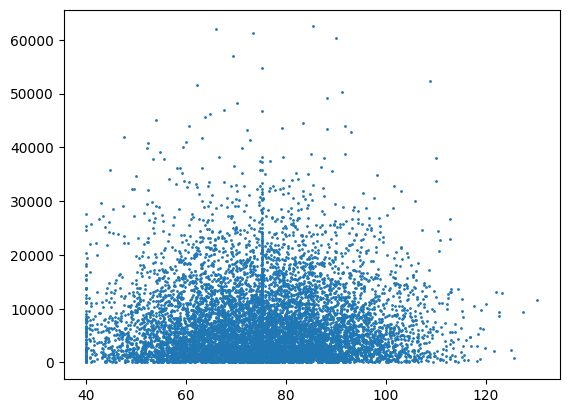

In [57]:
plt.scatter(final_table['Heart Rate (BPM)'],final_table['Step Count'],s=1)

**Question 14**: 


Read in the CSV table where we kept all the NaN values instead of removing or imputing them. Repeat the exact same visualization as above with this data. 

Compare the two figures. What do you notice?

ANSWER: I notice that the NaN plot extends further along the x-axis because the outliers are still there. The final_table plot presents a much more cohesive picture without the outliers; it makes more sense just looking at it, especially from a medical standpoint.

...

In [59]:
nanTable = pd.read_csv('smartwatch_nan_vals.csv')

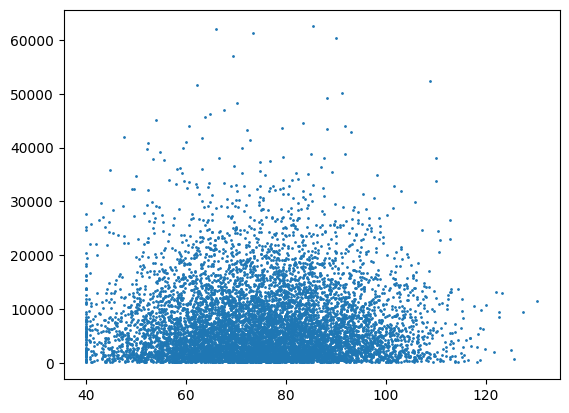

In [60]:
plt.scatter(nanTable['Heart Rate (BPM)'],nanTable['Step Count'],s=1)

**Question 15**: 


Does the amount of steps signficantly differ between the different activity level groups? 

Hint: Try using a boxplot (`sns.boxplot`) to first visualize the problem. Then you can use scipy.stats to run an ANOVA. 

Ellipsis

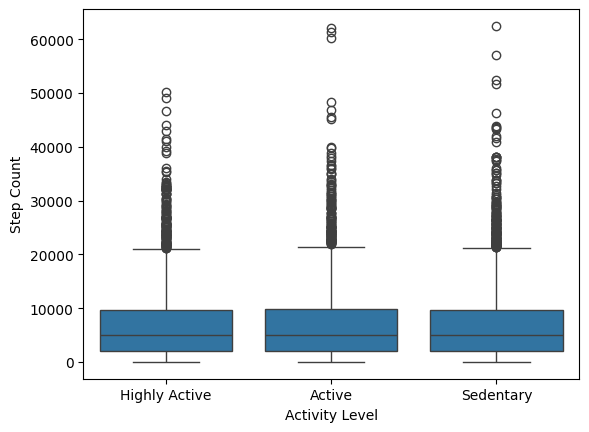

In [ ]:
## Visualization 
sns.boxplot(x='Activity Level', y='Step Count', data=final_table)
# https://stackoverflow.com/questions/49554139/boxplot-of-multiple-columns-of-a-pandas-dataframe-on-the-same-figure-seaborn


In [ ]:
active[active['Step Count'].isnull()]

,User ID,Heart Rate (BPM),Blood Oxygen Level (%),Step Count,Sleep Duration (hours),Activity Level,Stress Level,NumActivity
739,2649.0,97.506420,97.651407,NaN,7.465981,Active,6.0,2
1312,1242.0,74.978211,97.029676,NaN,7.592141,Active,6.0,2
1834,3981.0,56.312632,96.928926,NaN,7.405027,Active,10.0,2
2104,3041.0,88.245543,100.000000,NaN,4.119174,Active,7.0,2
2733,3003.0,53.224481,95.692628,NaN,11.188196,Active,8.0,2
3330,1042.0,69.261798,95.725957,NaN,7.809612,Active,5.0,2
3436,2940.0,46.929750,95.113305,NaN,8.733532,Active,9.0,2
3958,3361.0,105.249186,96.032065,NaN,5.315226,Active,2.0,2
4019,4750.0,82.749301,97.851229,NaN,6.743883,Active,7.0,2
4161,4711.0,99.168536,97.824395,NaN,7.291145,Active,3.0,2


In [ ]:
from scipy.stats import f_oneway


stat, pval = f_oneway(sedentary['Step Count'].dropna(), active['Step Count'].dropna(), highlyActive['Step Count'].dropna())


print(f"ANOVA test statistic: {stat:.3f}, p-value: {pval:.3f}")


ANOVA test statistic: 0.154, p-value: 0.857


Is there significant difference between the groups' step counts?  

ANSWER: There is not a significant difference between the groups' step counts. The means were about the same for each; interestingly, both the active and sedentary groups had a long trail away from the mean increasing in value while the highly active group did not.

**Question 16**

If you were to present your findings from this dataset to a broader audience (such as policymakers, healthcare providers, or the general public), how would you communicate key insights responsibly? What considerations would you take into account to avoid misrepresenting the data or reinforcing biases?

ANSWER: I would make sure to briefly describe the decisions I made in the data cleaning process for the purpose of transparency. I like the scatterplots and bar graphs more than the box plots because I feel like box plots are harder to intuitively understand just from looking at the graph. Scatterplots do a good job of showing relationships between two different variables, while bar graphs are good for looking at just one. I am a math major, and the avenue of mathematics I am interested in pursuing is modeling and simulations, so if I were to present this data, I would put it in R and explore various linear transformations as well as the Chebyshev and/or Least Squares approximation criterion so that I could model various relationships in the data. Maybe I could do that in Python! Not yet, though.

